
IMPROVED PSO PATH PLANNING
--------------------------------
Start point: [1. 1.]
Goal point: [9. 9.]

Optimized waypoints:
P1: (4.04, 2.50)
P2: (8.05, 6.80)
P3: (8.48, 7.64)
P4: (8.65, 8.03)

Path length: 11.668
Liquid influence cost: 3.356
Combined fitness: 15.024


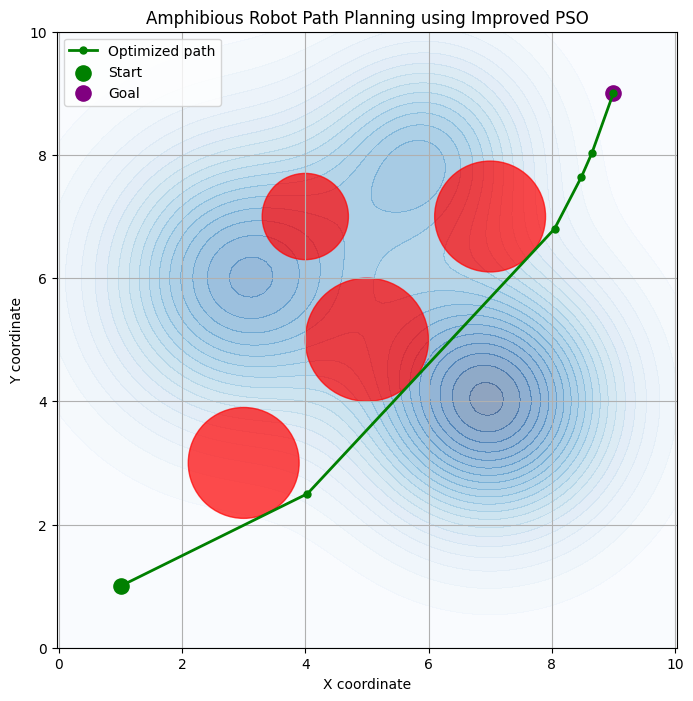

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

START = np.array([1.0, 1.0])
GOAL = np.array([9.0, 9.0])

NUM_PARTICLES = 30
NUM_WAYPOINTS = 4
MAX_ITERATIONS = 200

W1 = 1.0
W2 = 1.0

INERTIA_START = 0.9
INERTIA_END = 0.4
C1 = 2.0
C2 = 2.0

BOUNDS = (0.0, 10.0)

# Circular obstacles: (x, y, radius)
OBSTACLES = [
    (3.0, 3.0, 0.9),
    (5.0, 5.0, 1.0),
    (7.0, 7.0, 0.9),
    (4.0, 7.0, 0.7)
]

def liquid_influence(point):
    x, y = point

    influence = (
        0.8 * np.exp(-((x - 3.0)**2 + (y - 6.0)**2) / 5.0)
        + 1.0 * np.exp(-((x - 7.0)**2 + (y - 4.0)**2) / 4.0)
        + 0.6 * np.exp(-((x - 6.0)**2 + (y - 8.0)**2) / 3.0)
    )

    return influence

def path_length(path):
    distances = np.diff(path, axis=0)
    return np.sum(np.linalg.norm(distances, axis=1))

def evaluate_path(waypoints):
    path = np.vstack([START, waypoints, GOAL])

    length = path_length(path)
    liquid_cost = 0.0
    obstacle_penalty = 0.0

    # Sample each path segment to check safety
    for i in range(len(path) - 1):
        p1 = path[i]
        p2 = path[i + 1]

        segment_length = np.linalg.norm(p2 - p1)
        samples = max(10, int(segment_length * 20))

        for t in np.linspace(0, 1, samples):
            point = p1 + t * (p2 - p1)

            liquid_cost += liquid_influence(point) * (
                segment_length / samples
            )

            for ox, oy, radius in OBSTACLES:
                center = np.array([ox, oy])
                distance = np.linalg.norm(point - center)

                if distance < radius:
                    obstacle_penalty += (
                        (radius - distance) ** 2
                    ) * 1000

    fitness = (
        W1 * length
        + W2 * liquid_cost
        + obstacle_penalty
    )

    return fitness, length, liquid_cost

def pso_path_planning():
    dimension = NUM_WAYPOINTS * 2

    particles = np.random.uniform(
        BOUNDS[0], BOUNDS[1],
        (NUM_PARTICLES, dimension)
    )

    velocities = np.random.uniform(
        -1, 1, (NUM_PARTICLES, dimension)
    )

    personal_best = particles.copy()
    personal_fitness = np.full(NUM_PARTICLES, np.inf)

    global_best = None
    global_fitness = np.inf

    for iteration in range(MAX_ITERATIONS):
        inertia = INERTIA_START - (
            (INERTIA_START - INERTIA_END)
            * iteration / MAX_ITERATIONS
        )

        for i in range(NUM_PARTICLES):
            waypoints = particles[i].reshape(
                NUM_WAYPOINTS, 2
            )

            fitness, _, _ = evaluate_path(waypoints)

            if fitness < personal_fitness[i]:
                personal_fitness[i] = fitness
                personal_best[i] = particles[i].copy()

            if fitness < global_fitness:
                global_fitness = fitness
                global_best = particles[i].copy()

        r1 = np.random.random((NUM_PARTICLES, dimension))
        r2 = np.random.random((NUM_PARTICLES, dimension))

        velocities = (
            inertia * velocities
            + C1 * r1 * (personal_best - particles)
            + C2 * r2 * (global_best - particles)
        )

        velocities = np.clip(velocities, -1.5, 1.5)

        particles += velocities
        particles = np.clip(
            particles, BOUNDS[0], BOUNDS[1]
        )

    best_waypoints = global_best.reshape(
        NUM_WAYPOINTS, 2
    )

    return best_waypoints

def display_path(waypoints):
    path = np.vstack([START, waypoints, GOAL])

    fitness, length, liquid_cost = evaluate_path(waypoints)

    print("\nIMPROVED PSO PATH PLANNING")
    print("--------------------------------")
    print("Start point:", START)
    print("Goal point:", GOAL)
    print("\nOptimized waypoints:")

    for i, point in enumerate(waypoints, start=1):
        print(
            f"P{i}: ({point[0]:.2f}, {point[1]:.2f})"
        )

    print("\nPath length:", round(length, 3))
    print("Liquid influence cost:", round(liquid_cost, 3))
    print("Combined fitness:", round(fitness, 3))

    plt.figure(figsize=(8, 8))

    # Draw liquid-influence regions
    grid = np.linspace(0, 10, 100)
    X, Y = np.meshgrid(grid, grid)
    Z = np.zeros_like(X)

    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = liquid_influence(
                [X[i, j], Y[i, j]]
            )

    plt.contourf(X, Y, Z, levels=20, cmap="Blues",
                 alpha=0.45)

    # Draw obstacles
    for ox, oy, radius in OBSTACLES:
        circle = plt.Circle(
            (ox, oy), radius, color="red", alpha=0.7
        )
        plt.gca().add_patch(circle)

    plt.plot(
        path[:, 0], path[:, 1],
        "g-o", linewidth=2, markersize=5,
        label="Optimized path"
    )

    plt.scatter(
        START[0], START[1],
        color="green", s=120, label="Start"
    )

    plt.scatter(
        GOAL[0], GOAL[1],
        color="purple", s=120, label="Goal"
    )

    plt.xlim(0, 10)
    plt.ylim(0, 10)
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.title("Amphibious Robot Path Planning using Improved PSO")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")
    plt.show()

if __name__ == "__main__":
    best_path = pso_path_planning()
    display_path(best_path)
